# Does mild noise augmentation help the CNN?

Compare a clean CNN with a CNN that sees mild noise in 50% of its training windows. Both runs use the same number of windows, architecture, starting seed, class weights, and stopping rule. Noise is added before log-Mel conversion. Validation stays clean and the test split is excluded.

Place this notebook in the repo's `notebooks/` folder, select the `DS_env` kernel, and run the cells in order. If the split CSV is missing, make sure the raw dataset is in `data/raw/` and run these commands from the repo root:

```cmd
python -m src.preprocessing.create_indexes
python -m src.preprocessing.split_patients
```

The notebook reads the WAV files directly. Feature extraction and two CNN training runs can take a while on CPU. The notebook leaves the saved project models and results alone.

In [1]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
if not (root / "src" / "models" / "train_cnn.py").is_file():
    raise FileNotFoundError("Open the notebook from the repo root or its notebooks folder.")
sys.path.insert(0, str(root))

FIGURES_DIR = root / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

splits_path = root / "data" / "processed" / "recording_splits.csv"
if not splits_path.is_file():
    raise FileNotFoundError("Run create_indexes and split_patients from the repo root first.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from scipy.signal import butter, sosfiltfilt
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

plt.style.use("dark_background")

from src.config import LABELS, SAMPLE_RATE
from src.preprocessing.audio_preprocessing import iter_recording_windows
from src.models.features import extract_log_mel
from src.models.data_utils import SEED, encode_labels, make_predictions_table
from src.models.train_cnn import build_cnn, set_all_seeds, MAX_EPOCHS, PATIENCE
from src.evaluation.aggregate_patients import aggregate_patients

# Use the winning configuration from the repo's CNN tuning results.
FILTERS = (32, 64, 128)
DROPOUT = 0.3
LEARNING_RATE = 0.001
BATCH_SIZE = 32
NOISE_FRACTION = 0.50
SNR_DB = 25

recordings = pd.read_csv(splits_path, dtype={"patient_id": str})
assert recordings.groupby("patient_id")["split"].nunique().eq(1).all()
recordings = recordings[recordings["split"].isin(["train", "validation"])]
assert set(recordings["split"]) == {"train", "validation"}
print(recordings.groupby("split")["patient_id"].nunique())
print("TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))

split
train         659
validation    141
Name: patient_id, dtype: int64
TensorFlow GPUs: []


## Build the clean and noisy inputs

Use quiet, band-limited synthetic noise at **25 dB signal-to-noise ratio**. Select training windows with a seeded random draw, replace those windows in the augmented run, and keep their labels. Add noise only to real audio samples so zero padding stays zero.

In [2]:
rng = np.random.default_rng(SEED)
noise_filter = butter(4, [25, 800], btype="bandpass", fs=SAMPLE_RATE, output="sos")


def add_mild_noise(window, valid_samples):
    signal = window[:valid_samples]
    signal_rms = np.sqrt(np.mean(signal ** 2))
    if signal_rms == 0:
        return window

    noise = sosfiltfilt(noise_filter, rng.normal(size=valid_samples))
    noise_rms = np.sqrt(np.mean(noise ** 2))
    target_rms = signal_rms / (10 ** (SNR_DB / 20))

    noisy_window = window.copy()
    noisy_window[:valid_samples] += noise * (target_rms / noise_rms)
    return noisy_window


clean_train, noisy_train, clean_val = [], [], []
train_labels, val_rows = [], []
selected = 0
example = None

for i, (window, sample_rate, meta) in enumerate(iter_recording_windows(recordings), start=1):
    clean = extract_log_mel(window, sample_rate)
    if meta["split"] == "train":
        clean_train.append(clean)
        train_labels.append(meta["murmur_label"])
        if rng.random() < NOISE_FRACTION:
            noisy = add_mild_noise(window, meta["valid_samples"])
            augmented = extract_log_mel(noisy, sample_rate)
            noisy_train.append(augmented)
            selected += 1
            if example is None:
                example = (clean, augmented)
        else:
            noisy_train.append(clean)
    else:
        clean_val.append(clean)
        val_rows.append({
            "subject_id": meta["patient_id"],
            "recording_id": Path(meta["recording"]).stem,
            "location": meta["location"],
            "window_idx": meta["window_idx"],
            "split": "val",
            "true_label": meta["murmur_label"],
        })

    if i % 2000 == 0:
        print(f"Prepared {i:,} windows")

x_clean = np.stack(clean_train)[..., None]
x_noisy = np.stack(noisy_train)[..., None]
x_val = np.stack(clean_val)[..., None]
del clean_train, noisy_train, clean_val
val_windows = pd.DataFrame(val_rows)
y_train = encode_labels(train_labels)
y_val = encode_labels(val_windows["true_label"])

print(f"Training windows per run: {len(x_clean):,}")
print(f"Training windows selected for noise: {selected:,} ({selected / len(x_clean):.1%})")
print(f"Clean validation windows: {len(x_val):,}")

Prepared 2,000 windows
Prepared 4,000 windows
Prepared 6,000 windows
Prepared 8,000 windows
Prepared 10,000 windows
Prepared 12,000 windows
Prepared 14,000 windows
Prepared 16,000 windows
Training windows per run: 13,337
Training windows selected for noise: 6,620 (49.6%)
Clean validation windows: 2,710


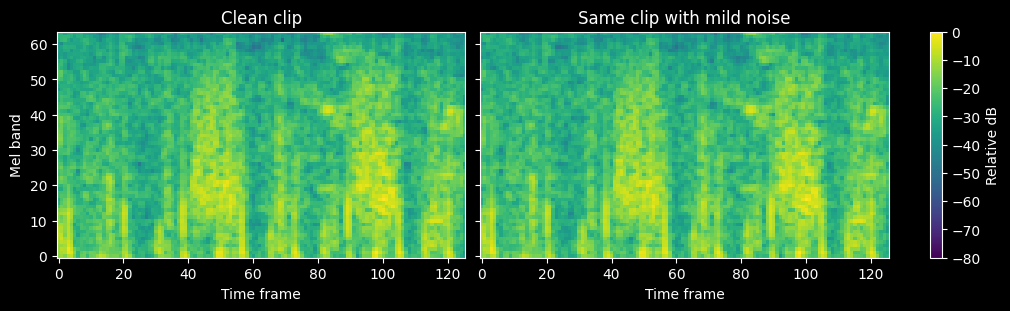

In [3]:
if example is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True, layout="constrained")
    for ax, mel, title in zip(axes, example, ["Clean clip", "Same clip with mild noise"]):
        plot = ax.imshow(mel, origin="lower", aspect="auto", vmin=-80, vmax=0)
        ax.set(title=title, xlabel="Time frame")
    axes[0].set_ylabel("Mel band")
    fig.colorbar(plot, ax=axes, label="Relative dB")
    fig.savefig(FIGURES_DIR / "noise_augmentation_example.png", dpi=200)
    plt.show()

## Train both CNNs

Fit the input normalization on the **clean training clips** in both runs. Use the same class weights and early stopping rule. Each run can stop at a different epoch based on clean validation loss.

In [4]:
classes = np.arange(len(LABELS))
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = dict(enumerate(weights))
train_targets = keras.utils.to_categorical(y_train, len(LABELS))
val_targets = keras.utils.to_categorical(y_val, len(LABELS))

patient_results = {}
histories = {}

for name, x_train in [("Clean CNN", x_clean), ("Noise-augmented CNN", x_noisy)]:
    print(f"Training {name}")
    keras.backend.clear_session()
    set_all_seeds()

    model = build_cnn(x_clean.shape[1:], x_clean, FILTERS, DROPOUT, LEARNING_RATE)
    stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True
    )
    history = model.fit(
        x_train, train_targets,
        validation_data=(x_val, val_targets),
        batch_size=BATCH_SIZE, epochs=MAX_EPOCHS,
        class_weight=class_weights, callbacks=[stop], verbose=2
    )
    histories[name] = pd.DataFrame(history.history)

    probabilities = model.predict(x_val, batch_size=BATCH_SIZE, verbose=0)
    window_predictions = make_predictions_table(val_windows, probabilities)
    patient_results[name] = aggregate_patients(window_predictions, "recording_mean")

Training Clean CNN

Epoch 1/40
417/417 - 7s - 17ms/step - accuracy: 0.3807 - loss: 1.0869 - val_accuracy: 0.4897 - val_loss: 1.0600
Epoch 2/40
417/417 - 6s - 15ms/step - accuracy: 0.5648 - loss: 1.0218 - val_accuracy: 0.7199 - val_loss: 0.8965
Epoch 3/40
417/417 - 6s - 14ms/step - accuracy: 0.5614 - loss: 0.9268 - val_accuracy: 0.7118 - val_loss: 0.7760
Epoch 4/40
417/417 - 7s - 16ms/step - accuracy: 0.5683 - loss: 0.8638 - val_accuracy: 0.7266 - val_loss: 0.7193
Epoch 5/40
417/417 - 6s - 15ms/step - accuracy: 0.5751 - loss: 0.8277 - val_accuracy: 0.7125 - val_loss: 0.7181
Epoch 6/40
417/417 - 6s - 15ms/step - accuracy: 0.5919 - loss: 0.7995 - val_accuracy: 0.7310 - val_loss: 0.6653
Epoch 7/40
417/417 - 6s - 15ms/step - accuracy: 0.5952 - loss: 0.7846 - val_accuracy: 0.6775 - val_loss: 0.7286
Epoch 8/40
417/417 - 6s - 14ms/step - accuracy: 0.6045 - loss: 0.7671 - val_accuracy: 0.7288 - val_loss: 0.6619
Epoch 9/40
417/417 - 6s - 14ms/step - accuracy: 0.6095 - loss: 0.7541 - val_accuracy

## Compare clean validation results at the patient level

Average window probabilities within each recording, then give each recording equal weight in the patient prediction. **Present recall** measures how many actual Present cases the model catches. **Macro-F1** gives each of the three labels equal weight.

,Validation patients,Accuracy,Macro-F1,Present recall,Present cases caught
Model,,,,,
Clean CNN,141,0.830,0.714,0.667,18/27
Noise-augmented CNN,141,0.809,0.686,0.630,17/27


Present recall change: -3.7 percentage points
Macro-F1 change: -0.029


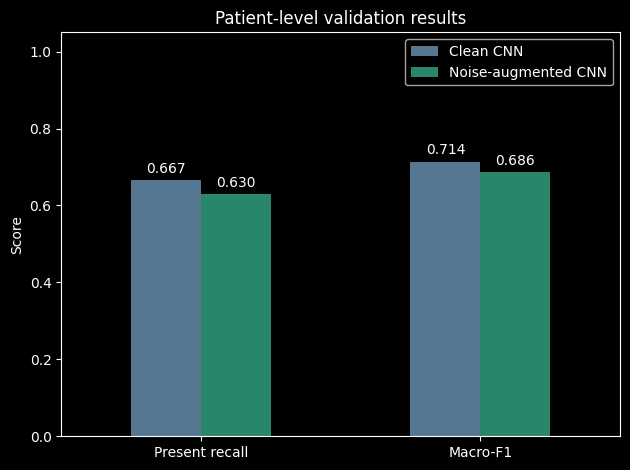

In [5]:
rows = []
for name, patients in patient_results.items():
    actual, predicted = patients["true_label"], patients["pred_label"]
    matrix = confusion_matrix(actual, predicted, labels=LABELS)
    present = LABELS.index("Present")
    caught = matrix[present, present]
    total = matrix[present].sum()
    rows.append({
        "Model": name,
        "Validation patients": len(patients),
        "Accuracy": accuracy_score(actual, predicted),
        "Macro-F1": f1_score(actual, predicted, labels=LABELS, average="macro", zero_division=0),
        "Present recall": caught / total if total else np.nan,
        "Present cases caught": f"{caught}/{total}",
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(3))

metrics = ["Present recall", "Macro-F1"]
change = results.loc["Noise-augmented CNN", metrics] - results.loc["Clean CNN", metrics]
print(f"Present recall change: {100 * change['Present recall']:+.1f} percentage points")
print(f"Macro-F1 change: {change['Macro-F1']:+.3f}")

ax = results[metrics].T.plot.bar(rot=0, ylim=(0, 1.05), color=["#557792", "#28866B"])
ax.set(title="Patient-level validation results", ylabel="Score")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "noise_augmentation_comparison.png", dpi=200)
plt.show()

The results indicate that utilizing data augmentation via mild noise does not improve the performance of the CNN.